Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 60.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 24.4 MB/s eta 0:00:00
✓ All dependencies installed and imported!

LOADING MODELS...
Loading image classification model...
✓ Image model loaded!

Loading text classification model...
Using device: cuda


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✓ Text model loaded!

Loading tokenizer...


✓ Tokenizer loaded!

Initializing EasyOCR...
Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete✓ OCR initialized!

ALL MODELS READY FOR INFERENCE!


🔍 SINGLE IMAGE ANALYSIS



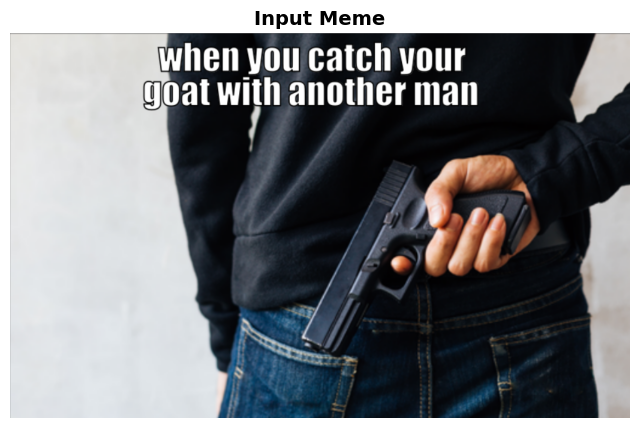


ANALYZING MEME...
1. Extracting text from image...
   Extracted: 'when VOU catch vour goat with another man'

2. Analyzing image content...
   Image Score: 0.4026

3. Analyzing text toxicity...
   Text Score: 0.1104

4. Computing combined score...
   Weights: Image=0.5, Text=0.5

FINAL RESULTS
Extracted Text: 'when VOU catch vour goat with another man'
Has Text: True

Image Score: 0.4026
Text Score: 0.1104
Combined Score: 0.2565

🎯 VERDICT: NOT HATEFUL
📊 Confidence: 74.35%


✅ READY TO ANALYZE MEMES!
💡 Tip: Change 'img_path' variable to analyze different images


In [ ]:
# ========================================
# HATEFUL MEME DETECTION - MERGE MODEL
# ========================================

# ========================================
# INSTALL DEPENDENCIES
# ========================================
!pip install -q torch transformers easyocr tensorflow pillow matplotlib

# ========================================
# IMPORTS
# ========================================
import torch
import numpy as np
import easyocr
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification
from PIL import Image
import matplotlib.pyplot as plt

# ========================================
# PATHS
# ========================================
MODEL_DIR = "/content/drive/MyDrive/DL_Projects/model"

IMAGE_MODEL_PATH = f"{MODEL_DIR}/best_hateful_meme_model.keras"
TEXT_MODEL_PATH = f"{MODEL_DIR}/best_distilbert_toxic.pth"
TOKENIZER_PATH = f"{MODEL_DIR}/distilbert_tokenizer"

# ========================================
# DEVICE
# ========================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# ========================================
# LOAD IMAGE MODEL
# ========================================
print("\nLoading image model...")

image_model = load_model(IMAGE_MODEL_PATH)

print("✓ Image model loaded!")

# ========================================
# LOAD TEXT MODEL
# ========================================
print("\nLoading text model...")

text_model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=2
)

text_model.load_state_dict(
    torch.load(
        TEXT_MODEL_PATH,
        map_location=device
    )
)

text_model = text_model.to(device)
text_model.eval()

print("✓ Text model loaded!")

# ========================================
# LOAD TOKENIZER
# ========================================
print("\nLoading tokenizer...")

tokenizer = DistilBertTokenizer.from_pretrained(
    TOKENIZER_PATH
)

print("✓ Tokenizer loaded!")

# ========================================
# INITIALIZE OCR
# ========================================
print("\nInitializing EasyOCR...")

reader = easyocr.Reader(
    ['en'],
    gpu=torch.cuda.is_available()
)

print("✓ OCR initialized!")

print("\n" + "=" * 60)
print("ALL MODELS READY!")
print("=" * 60)


# ========================================
# OCR
# ========================================
def extract_text_from_image(image_path):
    """Extract text from a meme using EasyOCR."""
    try:
        result = reader.readtext(image_path, detail=0)
        text = ' '.join(result)
        return text.strip()

    except Exception as e:
        print(f"OCR error: {e}")
        return ""


# ========================================
# IMAGE PREDICTION
# ========================================
def predict_image_hateful(img_path, model):
    """Return the hateful probability from the image model."""

    img = image.load_img(
        img_path,
        target_size=(224, 224)
    )

    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(
        img_array,
        verbose=0
    )[0][0]

    return float(prediction)


# ========================================
# TEXT PREDICTION
# ========================================
def predict_text_toxic(text, model, tokenizer, device):
    """Return the toxic probability from DistilBERT."""

    if not text or len(text.strip()) == 0:
        return 0.0

    model.eval()

    encoding = tokenizer(
        text,
        add_special_tokens=True,
        max_length=128,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)

    with torch.no_grad():
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        toxic_probability = probabilities[0][1].item()

    return toxic_probability


# ========================================
# COMBINED MEME PREDICTION
# ========================================
def analyze_meme(
    img_path,
    image_model,
    text_model,
    tokenizer,
    device,
    image_weight=0.5,
    text_weight=0.5,
    display_image=True
):
    """Analyze a meme using image + OCR text."""

    if display_image:
        img = Image.open(img_path)

        plt.figure(figsize=(8, 6))
        plt.imshow(img)
        plt.axis("off")
        plt.title("Input Meme")
        plt.show()

    print("\n" + "=" * 60)
    print("ANALYZING MEME")
    print("=" * 60)

    # OCR
    print("\n1. Extracting text...")
    extracted_text = extract_text_from_image(img_path)
    print(f"Extracted Text: '{extracted_text}'")

    # Image prediction
    print("\n2. Analyzing image...")
    image_pred = predict_image_hateful(
        img_path,
        image_model
    )

    print(f"Image Score: {image_pred:.4f}")

    # Text prediction
    print("\n3. Analyzing text...")
    text_pred = predict_text_toxic(
        extracted_text,
        text_model,
        tokenizer,
        device
    )

    print(f"Text Score: {text_pred:.4f}")

    # Combine
    print("\n4. Combining predictions...")

    if not extracted_text:
        combined_score = image_pred
        print("No text detected → using image score only.")

    else:
        combined_score = (
            image_weight * image_pred +
            text_weight * text_pred
        )

    final_label = (
        "HATEFUL MEME"
        if combined_score > 0.5
        else "NOT HATEFUL"
    )

    confidence = (
        combined_score * 100
        if combined_score > 0.5
        else (1 - combined_score) * 100
    )

    print("\n" + "=" * 60)
    print("FINAL RESULTS")
    print("=" * 60)

    print(f"Extracted Text: '{extracted_text}'")
    print(f"Has Text: {bool(extracted_text)}")
    print(f"Image Score: {image_pred:.4f}")
    print(f"Text Score: {text_pred:.4f}")
    print(f"Combined Score: {combined_score:.4f}")
    print(f"Verdict: {final_label}")
    print(f"Confidence: {confidence:.2f}%")

    print("=" * 60)

    return {
        'image_path': img_path,
        'extracted_text': extracted_text,
        'image_prediction': float(image_pred),
        'text_prediction': float(text_pred),
        'combined_score': float(combined_score),
        'final_label': final_label,
        'confidence': float(confidence),
        'has_text': bool(extracted_text)
    }



🔍 SINGLE IMAGE ANALYSIS



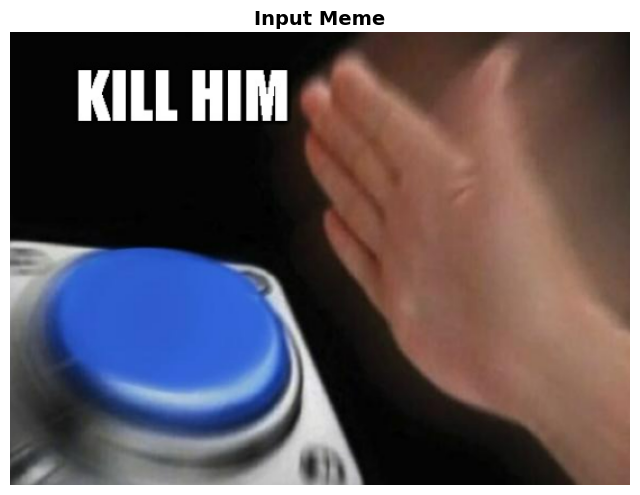


ANALYZING MEME...
1. Extracting text from image...
   Extracted: 'KILL HIM'

2. Analyzing image content...
   Image Score: 0.3479

3. Analyzing text toxicity...
   Text Score: 0.9563

4. Computing combined score...
   Weights: Image=0.5, Text=0.5

FINAL RESULTS
Extracted Text: 'KILL HIM'
Has Text: True

Image Score: 0.3479
Text Score: 0.9563
Combined Score: 0.6521

🎯 VERDICT: HATEFUL MEME
📊 Confidence: 65.21%

Processing Image 1/3


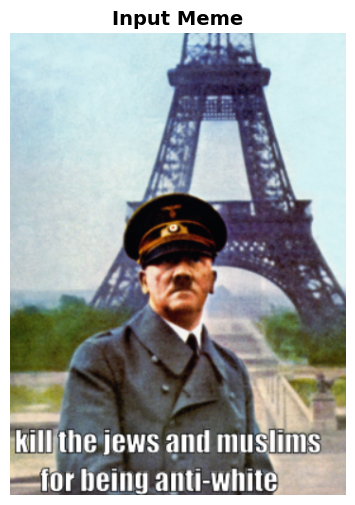


ANALYZING MEME...
1. Extracting text from image...
   Extracted: 'kill the jews and muslns for being anti-white'

2. Analyzing image content...
   Image Score: 0.3129

3. Analyzing text toxicity...
   Text Score: 0.7973

4. Computing combined score...
   Weights: Image=0.5, Text=0.5

FINAL RESULTS
Extracted Text: 'kill the jews and muslns for being anti-white'
Has Text: True

Image Score: 0.3129
Text Score: 0.7973
Combined Score: 0.5551

🎯 VERDICT: HATEFUL MEME
📊 Confidence: 55.51%

Processing Image 2/3


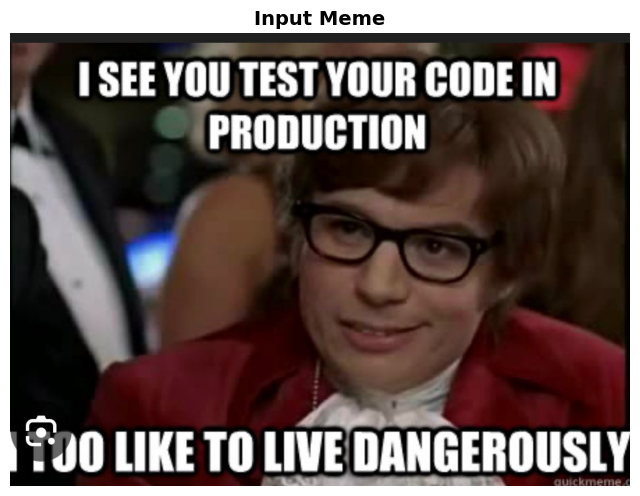


ANALYZING MEME...
1. Extracting text from image...
   Extracted: 'ISEE YOU TEST YOUR CODE IN PRODUCTION 8Jo LIKE TO LIVEDANGEROUSLY uckanene'

2. Analyzing image content...
   Image Score: 0.4102

3. Analyzing text toxicity...
   Text Score: 0.0190

4. Computing combined score...
   Weights: Image=0.5, Text=0.5

FINAL RESULTS
Extracted Text: 'ISEE YOU TEST YOUR CODE IN PRODUCTION 8Jo LIKE TO LIVEDANGEROUSLY uckanene'
Has Text: True

Image Score: 0.4102
Text Score: 0.0190
Combined Score: 0.2146

🎯 VERDICT: NOT HATEFUL
📊 Confidence: 78.54%

Processing Image 3/3


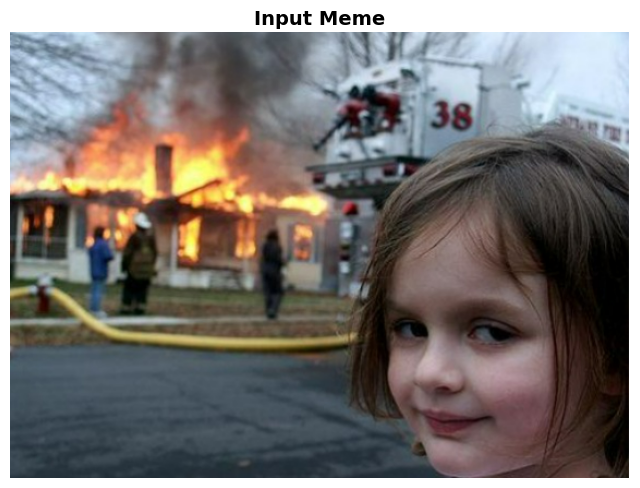


ANALYZING MEME...
1. Extracting text from image...
   Extracted: '38'

2. Analyzing image content...
   Image Score: 0.3838

3. Analyzing text toxicity...
   Text Score: 0.0025

4. Computing combined score...
   Weights: Image=0.5, Text=0.5

FINAL RESULTS
Extracted Text: '38'
Has Text: True

Image Score: 0.3838
Text Score: 0.0025
Combined Score: 0.1931

🎯 VERDICT: NOT HATEFUL
📊 Confidence: 80.69%

SUMMARY OF ALL IMAGES
1. HATEFUL MEME (55.5%)
2. NOT HATEFUL (78.5%)
3. NOT HATEFUL (80.7%)


✅ READY TO ANALYZE MEMES!
💡 Tip: Change 'img_path' variable to analyze different images


In [ ]:
# ========================================
# RUN MEME PREDICTIONS
# ========================================

# Single image prediction
img_path = "/content/drive/MyDrive/DL_Project/image5.jpeg"

results = analyze_meme(
    img_path,
    image_model,
    text_model,
    tokenizer,
    device,
    image_weight=0.5,
    text_weight=0.5,
    display_image=True
)


# ========================================
# BATCH PREDICTION
# ========================================
def analyze_multiple_memes(image_paths):
    """Analyze multiple meme images."""

    results_list = []

    for i, img_path in enumerate(image_paths):

        print("\n" + "=" * 60)
        print(f"Processing Image {i + 1}/{len(image_paths)}")
        print("=" * 60)

        result = analyze_meme(
            img_path,
            image_model,
            text_model,
            tokenizer,
            device,
            image_weight=0.5,
            text_weight=0.5,
            display_image=True
        )

        results_list.append(result)

    return results_list


# Example batch prediction
image_list = [
    "/content/drive/MyDrive/DL_Project/image1.jpeg",
    "/content/drive/MyDrive/DL_Project/image2.jpeg",
    "/content/drive/MyDrive/DL_Project/image3.jpeg"
]

all_results = analyze_multiple_memes(image_list)


# ========================================
# BATCH SUMMARY
# ========================================
print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)

for i, result in enumerate(all_results):
    print(
        f"{i + 1}. "
        f"{result['final_label']} "
        f"({result['confidence']:.1f}%)"
    )

In [ ]:
# ========================================
# TEXT-ONLY TOXICITY ANALYSIS
# ========================================
def analyze_text_only(
    text,
    model,
    tokenizer,
    device,
    display_details=True
):
    """Analyze a text string for toxicity."""

    if not text or len(text.strip()) == 0:
        print("Empty text provided!")
        return None

    toxic_score = predict_text_toxic(
        text,
        model,
        tokenizer,
        device
    )

    is_toxic = toxic_score > 0.5

    label = (
        "TOXIC"
        if is_toxic
        else "NOT TOXIC"
    )

    confidence = (
        toxic_score * 100
        if is_toxic
        else (1 - toxic_score) * 100
    )

    if toxic_score < 0.3:
        severity = "Safe"
    elif toxic_score < 0.5:
        severity = "Borderline"
    elif toxic_score < 0.7:
        severity = "Toxic"
    else:
        severity = "Highly Toxic"

    if display_details:
        print("\n" + "=" * 60)
        print("TEXT ANALYSIS")
        print("=" * 60)
        print(f"Input: {text}")
        print(f"Toxicity Score: {toxic_score:.4f}")
        print(f"Verdict: {label}")
        print(f"Confidence: {confidence:.2f}%")
        print(f"Severity: {severity}")
        print("=" * 60)

    return {
        'text': text,
        'toxic_score': float(toxic_score),
        'label': label,
        'confidence': float(confidence),
        'severity': severity,
        'is_toxic': is_toxic
    }

In [ ]:
# ========================================
# MANUAL TEXT TOXICITY TEST
# ========================================

manual_text = "You are stupid"

result = analyze_text_only(
    manual_text,
    text_model,
    tokenizer,
    device
)



📝 MANUAL TEXT TOXICITY PREDICTION

Analyzing text: 'You are stupid'

ANALYZING TEXT...
Input: 'You are stupid'
Length: 14 characters

RESULTS
Toxicity Score: 0.9827
Verdict: TOXIC
Confidence: 98.27%
Severity: 🔴🔴 Highly Toxic
